### Top Rows

In [332]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="kPEX")
# df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3 v4".split()
versions="v0 v1 v2 v3".split()
branchings="S R P".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/6664473.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/6664473.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/6664473.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the ol

In [347]:
# for v in versions: 
cols = [f"v0-{b}-mkp" for b in "S R P".split() ]
cols = [f"v{i}-{b}-mkp" for i in [0, 1] for b in "S R P".split() ]

mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
display_scroll(df.loc[mask, cols+["dataset", "k", "v1-S-total"]])
filtered_df = df[mask]

filtered_df[["dataset", "k"]].to_excel("filtered_rows.xlsx", index=False)
mask.sum()

,v0-S-mkp,v0-R-mkp,v0-P-mkp,v1-S-mkp,v1-R-mkp,v1-P-mkp,dataset,k,v1-S-total
9,17,15,15,15,15,15,145bit,9,42.2
60,40,40,40,39,39,39,3dtube,15,74.6
403,38,38,38,37,37,37,bcsstk16,15,242.9
411,38,37,37,37,37,37,bcsstk29,15,1.4
443,40,41,40,39,39,39,bcsstk39,20,30.2
448,39,30,30,30,30,30,bcsstm34,20,1.7
450,101,101,100,100,100,100,beacxc,4,0.9
457,101,102,100,100,100,100,beaflw,4,3.2
461,114,113,113,113,113,113,beaflw,8,1.2
468,89,88,88,88,88,88,beause,6,1.5


np.int64(136)

### Varying Ratio Threshold


=== Threshold 1.5 Analysis ===
v0-init wins: 158
v2-init wins: 909

--- Weaker side: v0-init ---


,dataset,k,v0-init,v2-init,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
4173,web-wikipedia_link_en13-a...,5,587.5,1334.1,2.27x,563.6,574.0,23.9,760.1,587.5,1334.1,True,,583.6,1385.2,595.9,1269.1,583.0,1348.4
4218,wikipedia-link-en13,5,563.2,1285.6,2.28x,539.5,542.5,23.6,743.0,563.2,1285.6,True,,542.5,1275.1,582.1,1270.3,564.9,1311.8
4172,web-wikipedia_link_en13-a...,4,460.3,942.9,2.05x,334.9,358.1,125.4,584.8,460.3,942.9,True,,466.5,921.6,448.4,937.7,466.1,970.0
4217,wikipedia-link-en13,4,448.1,904.1,2.02x,323.9,333.5,124.2,570.6,448.1,904.1,True,,447.3,890.7,435.2,943.3,461.9,878.7
1964,livejournal-groupmembersh...,9,404.1,849.3,2.10x,282.9,293.5,121.2,555.8,404.1,849.3,,,471.5,1008.4,476.9,1013.5,423.1,977.4
3486,soc-livejournal-user-grou...,9,398.4,869.0,2.18x,279.4,301.6,119.0,567.5,398.4,869.0,,,451.6,1029.1,463.7,1024.2,433.5,1008.0
3484,soc-livejournal-user-grou...,7,297.9,863.3,2.90x,207.9,235.7,90.1,627.6,297.9,863.3,,,352.8,1054.6,358.5,1087.4,403.9,968.3
1962,livejournal-groupmembersh...,7,285.7,845.3,2.96x,199.3,229.5,86.4,615.8,285.7,845.3,,,352.7,976.5,363.5,963.6,356.5,1114.6
3485,soc-livejournal-user-grou...,8,155.3,351.3,2.26x,113.0,132.6,42.3,218.6,155.3,351.3,,,218.8,499.8,223.9,512.9,217.3,545.8
1963,livejournal-groupmembersh...,8,140.8,308.2,2.19x,101.3,109.3,39.5,198.9,140.8,308.2,,,213.8,467.7,196.9,467.1,199.5,468.7



--- Stronger side: v2-init ---


,dataset,k,v0-init,v2-init,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
4278,wikipedia_link_sr,4,202.9,50.2,4.04x,37.6,44.3,165.2,5.9,202.9,50.2,True,,204.3,59.8,202.0,60.2,202.3,60.7
4277,wikipedia_link_sr,3,254.8,50.1,5.09x,43.6,44.1,211.1,5.9,254.8,50.1,,,265.9,59.1,253.6,58.1,271.6,59.2
4286,wikipedia_link_sr,20,221.7,45.8,4.84x,42.8,45.7,178.9,0.1,221.7,45.8,True,True,222.4,44.9,221.6,44.4,221.0,48.0
4282,wikipedia_link_sr,8,233.9,45.0,5.19x,44.0,45.0,189.9,0.1,233.9,45.0,True,True,225.2,44.6,231.2,44.3,245.1,46.3
4285,wikipedia_link_sr,15,223.7,44.6,5.01x,43.6,44.6,180.1,0.1,223.7,44.6,True,True,233.0,45.4,218.2,44.8,219.9,43.7
4284,wikipedia_link_sr,10,221.7,44.5,4.98x,43.6,44.4,178.0,0.1,221.7,44.5,True,True,214.8,44.7,218.2,44.0,232.0,44.9
4283,wikipedia_link_sr,9,225.4,44.2,5.10x,42.6,44.1,182.9,0.1,225.4,44.2,True,True,226.3,44.7,224.7,43.3,225.2,44.6
4281,wikipedia_link_sr,7,224.5,44.0,5.10x,43.6,44.0,180.9,0.1,224.5,44.0,True,True,215.5,44.4,225.0,43.3,232.9,44.4
4280,wikipedia_link_sr,6,231.2,44.0,5.26x,43.2,43.9,188.0,0.1,231.2,44.0,True,True,238.0,43.3,231.9,43.9,223.8,44.7
910,delicious-ui,5,73.7,40.1,1.84x,35.5,37.6,38.2,2.5,73.7,40.1,,,103.3,466.3,117.3,451.1,111.9,467.6


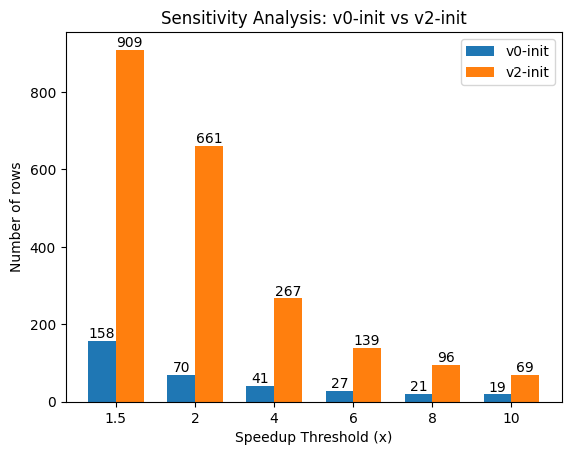

In [333]:
# =========================
# CONFIG
# =========================

col_a = "v0-init"
col_b = "v2-init"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [1.5, 2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================
df_filtered = df[
    (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
].copy()

# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = thresholds[0]

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# =========================
# Determine weaker & stronger
# =========================
if len(a_wins) < len(b_wins):
    weaker = "A"
    stronger = "B"
elif len(b_wins) < len(a_wins):
    weaker = "B"
    stronger = "A"
else:
    weaker = "Tie"
    stronger = "Tie"


# =========================
# Formatting function (SIDE-AWARE)
# =========================
max_len = 25

def format_df(df_in, side):
    if side == "A":
        speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_b}/{col_a}"
    else:
        speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_a}/{col_b}"

    return df_in.assign(
        dataset=df_in["dataset"].apply(
            lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
        ),
        speedup=speedup_series
    )[[
        "dataset", "k",
        col_a, col_b,
        "speedup",
        f"{va}-ctcp", f"{vb}-ctcp",
        f"{va}-heur", f"{vb}-heur",
        f"{va}-init", f"{vb}-init",
        f"{va}-prep", f"{vb}-prep",
        f"{va}-S-total", f"{vb}-S-total",
        f"{va}-R-total", f"{vb}-R-total",
        f"{va}-P-total", f"{vb}-P-total"
    ]]
    # .rename(columns={"speedup": f"speedup ({speedup_name})"})

# =========================
# Print summary
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

# =========================
# Display results
# =========================
if weaker == "Tie":
    print("Both sides have equal wins.")

    print("\n--- Side A (>= threshold) ---")
    display_scroll(
        format_df(a_wins.sort_values(by=f"{col_a}", ascending=False), "A")
        # format_df(a_wins.sort_values(by="{speedup_a}", ascending=False), "A")
    )

    print("\n--- Side B (>= threshold) ---")
    display_scroll(
        format_df(b_wins.sort_values(by=f"{col_b}", ascending=False), "B")
        # format_df(a_wins.sort_values(by="{speedup_b}", ascending=False), "A")
    )

else:
    if weaker == "A":
        weaker_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        stronger_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        # weaker_df = a_wins.sort_values(by="speedup_a", ascending=False)
        # stronger_df = b_wins.sort_values(by="speedup_b", ascending=False)
        weaker_name, stronger_name = col_a, col_b

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "A"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "B"))

    else:
        weaker_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        stronger_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        # weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
        # stronger_df = a_wins.sort_values(by="speedup_a", ascending=False)
        weaker_name, stronger_name = col_b, col_a

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "B"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "A"))

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()